<a href="https://colab.research.google.com/github/anordonezc/Lab-Calculo-D/blob/main/L2_sesion1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía L2 — El índice sancocho · **Sesión 1: la receta como función**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> Esta idea nació un domingo en Berlín, entre un döner y el recuerdo de una bullabesa. La historia completa está en la guía: este cuaderno es la sobremesa vuelta código.

**Uso en Colab:** guarden su copia (`Archivo → Guardar una copia en Drive`) y renómbrenla `L2_apellidos.ipynb`. Las celdas marcadas con ✏️ invitan a explorar o modificar; las marcadas con 🗣️ son para escribir conclusiones del equipo.

---
## ⏸️ Momento 1 — Predecir

Antes de ejecutar, respondan P1, P2 y P3 de la guía en papel: el costo del sancocho para seis en Manizales, si manda el espinazo o el resto de la olla, y si subió más la papa o el plátano. Foto al informe.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Precios mayoristas mensuales de SIPSA-DANE, congelados por el curso.
# El archivo .csv.gz se lee directamente: pandas reconoce la compresión.
RUTA = (
    "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/"
    "main/datos/sipsa_mensual.csv.gz"
)
df = pd.read_csv(RUTA)

print("Filas y columnas:", df.shape)
df.head(8)

Filas y columnas: (666865, 5)


,fecha,ciudad,mercado,producto,precio_kg
0,2013-01,Armenia,"Armenia, Frigocafé",Carne de cerdo en canal,6320.0
1,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, brazo con hueso",8520.0
2,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, brazo sin hueso",9000.0
3,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, cabeza de lomo",9020.0
4,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, costilla",9020.0
5,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, espinazo",6520.0
6,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, lomo con hueso",11020.0
7,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, lomo sin hueso",12020.0


---
## 1 · El ritual, ya sin niñera

En L1 lo hicimos juntos; hoy es de ustedes. El objetivo es decidir qué valores acepta cada columna, buscar valores ilegales y entender el alcance del congelado. Después, busquen los nombres oficiales de los ingredientes: los datos no saben cómo los llamamos en la casa.

🗣️ Escriban como comentario sus decisiones sobre los valores faltantes, precios no positivos y filas repetidas. ¿Una fila por `(fecha, mercado, producto)` es lo esperado?

In [ ]:
df.isna().sum()
(df["precio_kg"] <= 0).sum()
df.duplicated(["fecha", "mercado", "producto"]).sum()

# DECISIONES EN COMENTARIOS:
# 1. Nulos: Eliminar filas incompletas con df.dropna().
# 2. Precios &lt;= 0: Filtrar valores ilegales con df[df["precio_kg"] &gt; 0].
# 3. Duplicados: Eliminar filas repetidas con df.drop_duplicates().

np.int64(0)

In [ ]:
# ✏️ Ejercicio 1 — Completen la auditoría y dejen sus decisiones en comentarios.
print("Productos distintos:", df["producto"].nunique())
print("Ciudades:", df["ciudad"].nunique())
print("Meses: de", df["fecha"].min(), "a", df["fecha"].max())
print("\nTipos de dato:\n", df.dtypes)
print("\nValores faltantes por columna:\n", df.isna().sum())
print("\nPrecios medios no positivos:", (df["precio_kg"] <= 0).sum())
print("Filas repetidas por fecha, mercado y producto:",
      df.duplicated(["fecha", "mercado", "producto"]).sum())

# ¿Qué dominio matemático le asignan a fecha, ciudad, mercado, producto y precio_kg?
# A fecha se le aisgna un d e N30, un m e Z12 y un a que pertence a N, tal que d = dia, m = mes y a = año.A ciudad un elemento que pertenece a N, para asignar un codigo.  A mercado un elemento que pertenece a N, para asignar un codigo de mercado
# y con el producto seria igual, un elemento que pertenece a N para crear un codigo. Con el precio/kg se le asinga un elemento x e N y este se evalua en p/x

Productos distintos: 385
Ciudades: 71
Meses: de 2013-01 a 2024-12

Tipos de dato:
 fecha         object
ciudad        object
mercado       object
producto      object
precio_kg    float64
dtype: object

Valores faltantes por columna:
 fecha        0
ciudad       0
mercado      0
producto     0
precio_kg    0
dtype: int64

Precios medios no positivos: 0
Filas repetidas por fecha, mercado y producto: 0


In [ ]:
# ✏️ Ejercicio 2 — Cambien `busca` e iteren.
# Encuentren los nombres oficiales de espinazo, yuca, papa, mazorca y plátano verde.
# Luego restrinjan la búsqueda a Manizales: no todas las variedades se venden allí.
busca = input("Que nombre exacto deseas buscar: ")
coincidencias = df.loc[
    df["producto"].str.contains(busca, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print(coincidencias["producto"].drop_duplicates().to_list())

# Pista para Manizales:
# df.loc[(df["ciudad"] == "Manizales") &
#        df["producto"].str.contains(busca, case=False, na=False), "producto"].unique()

Que nombre exacto deseas buscar: Pollo
['Alas de pollo sin costillar', 'Menudencias de pollo', 'Pechuga de pollo', 'Piernas de pollo', 'Pollo entero fresco sin vísceras', 'Rabadillas de pollo', 'Repollo blanco', 'Alas de pollo con costillar', 'Pollo entero congelado sin vísceras', 'Muslos de pollo sin rabadilla', 'Repollo morado', 'Repollo verde', 'Sopa de pollo (caja)', 'Repollo blanco bogotano', 'Pollo entero fresco con vísceras', 'Muslos de pollo con rabadilla', 'Pollo entero congelado con vísceras', 'Repollo blanco valluno']


In [ ]:
# ✏️ Ejercicio 2 — Cambien `busca` e iteren.
# Encuentren los nombres oficiales de espinazo, yuca, papa, mazorca y plátano verde.
# Luego restrinjan la búsqueda a Manizales: no todas las variedades se venden allí.
busca = "pollo"
coincidencias = df.loc[(df["ciudad"] == "Manizales") & df["producto"].str.contains(busca, case=False, na=False), "producto"].unique()

print(list(coincidencias))

['Repollo blanco', 'Repollo verde', 'Pechuga de pollo', 'Rabadillas de pollo', 'Repollo blanco bogotano', 'Piernas de pollo']


---
## 2 · La receta en código

La receta oficial es para seis personas. Cada valor está en kilogramos, que es la unidad del mercado: 1,5 kg de espinazo, 1 kg de yuca, 1 kg de papa, 0,9 kg de mazorca y 1,4 kg de plátano. Traducir de unidades de cocina a kilogramos también es una función.

In [ ]:
RECETA = {
    "Pechuga de pollo":               0.2,
    "Carne de cerdo, costilla":       0.15,
    "Arveja verde en vaina":          0.1,
    "Arroz de primera":               0.3,
    "Harina precocida de maíz":       0.1,
}
print("Ingredientes:", len(RECETA), "| Kilos totales:", sum(RECETA.values()))

# ✏️ Confirmen que cada nombre existe para Manizales antes de seguir.

Ingredientes: 5 | Kilos totales: 0.85


---
## 3 · El pipeline, pieza por pieza

Estas cuatro funciones son puras: reciben una tabla y sus parámetros, y devuelven una tabla o un número. No dependen de `df`, `RECETA` ni ninguna otra variable externa. Lean cada contrato, prueben cada función por separado y luego sigan el dato a través de la composición.

In [ ]:
def filtrar_ciudad(tabla, ciudad):
    """tabla → tabla: conserva únicamente las filas de una ciudad."""
    return tabla.loc[tabla["ciudad"] == ciudad].copy()

def filtrar_mes(tabla, fecha):
    """tabla → tabla: conserva únicamente el mes AAAA-MM indicado."""
    return tabla.loc[tabla["fecha"] == fecha].copy()

def filtrar_productos(tabla, receta):
    """tabla → tabla: conserva los productos que aparecen en la receta."""
    return tabla.loc[tabla["producto"].isin(receta)].copy()

def costear(tabla, receta):
    """tabla → número: suma kilos × precio_kg de cada ingrediente."""
    precios = tabla.groupby("producto")["precio_kg"].mean()
    faltantes = [producto for producto in receta if producto not in precios]
    if faltantes:
        raise ValueError(f"Faltan ingredientes: {faltantes}")
    return sum(kilos * precios[producto] for producto, kilos in receta.items())

# ✏️ ¿Por qué `.isin(receta)` sirve para varios productos y `== receta` no?
# Porque al usar .isin, compara uno por uno los elementos de el diccionario, al poner ==, quisieramos comparar el diccionario con el valor receta
# ¿En qué situación habría varias filas del mismo ingrediente y por qué usamos `mean`?
# Porque por fechas los precios cambian, entonces en cada fila se registra una fecha distinta con un valor distinto de ingrediente. Mean promedia estos valores dando un precio promedio

In [ ]:
# Una función que fabrica la función compuesta.
def componer(*funciones):
    def compuesta(x):
        for funcion in funciones:
            x = funcion(x)
        return x
    return compuesta

CIUDAD = "Manizales"
MES = df.loc[df["ciudad"] == CIUDAD, "fecha"].max()

costo_sancocho = componer(
    lambda tabla: filtrar_ciudad(tabla, CIUDAD),
    lambda tabla: filtrar_mes(tabla, MES),
    lambda tabla: filtrar_productos(tabla, RECETA),
    lambda tabla: costear(tabla, RECETA),
)

print(f"Mercado del sancocho en {CIUDAD}, {MES}: ${costo_sancocho(df):,.0f}")

# ✏️ Dibujen el recorrido de `df` por las cuatro funciones.
# Tabla Original: 1. lambda tabla: filtrar_ciudad(tabla, CIUDAD)
# Solo Datos de Manizales: 2. lambda tabla: filtrar_mes(tabla, MES)
# El mes mas reciente: 3. lambda tabla: filtrar_productos(tabla, RECETA)
# Solamente los ingredientes de la receta: 4. lambda tabla: costear(tabla, RECETA)
# ¿Por qué una lambda permite fijar ciudad, mes y receta sin romper la pureza de las funciones?
#  Porque asi la funcion no depende de variables globales, sino de variables (En este caso las funciones lambda) que estan en constante cambio

Mercado del sancocho en Manizales, 2024-12: $8,437


🗣️ **Confronten P1:** ¿quién tuvo el mejor ojo de mercado? Los datos son precios mayoristas de una central de abastos: ¿el mercado de la esquina cobraría más o menos y por qué?


**Confrontacion**

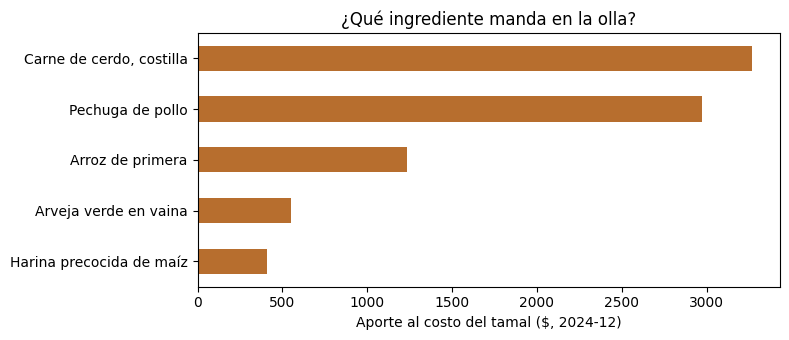

La costilla aporta $3,269 de $8,437: 39% de la olla.


In [ ]:
# ¿Qué ingrediente manda? Confronten P2 con los aportes al costo.
mes_tabla = filtrar_productos(
    filtrar_mes(filtrar_ciudad(df, CIUDAD), MES), RECETA
)
precios_mes = mes_tabla.groupby("producto")["precio_kg"].mean()
aportes = pd.Series({
    producto: kilos * precios_mes[producto]
    for producto, kilos in RECETA.items()
}).sort_values()

ax = aportes.plot.barh(figsize=(8, 3.5), color="#B76E2E")
ax.set_xlabel(f"Aporte al costo del tamal ($, {MES})")
ax.set_title("¿Qué ingrediente manda en la olla?")
plt.tight_layout()
plt.show()

total = aportes.sum()
espinazo = aportes["Carne de cerdo, costilla"]
print(f"La costilla aporta ${espinazo:,.0f} de ${total:,.0f}: {100 * espinazo / total:.0f}% de la olla.")

# ✏️ Para P3, cambien la receta a solo papa y plátano; comparen el primer y último mes.

Ingredientes: 2 | Kilos totales: 1.2


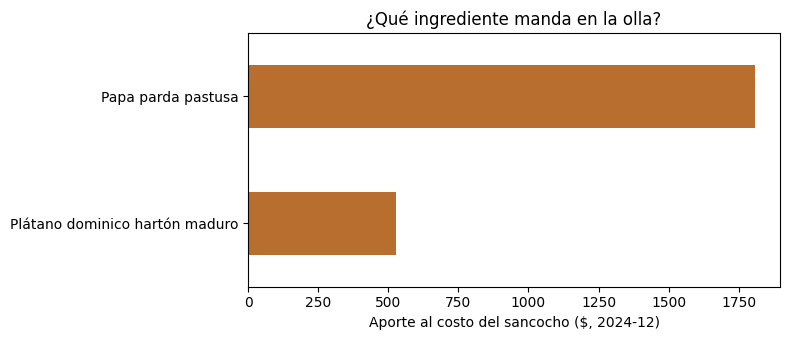

La papa aporta $1,807 de $2,336: 77% de la olla.


In [ ]:

RECETA = {
    "Plátano dominico hartón maduro":               0.2,
    "Papa parda pastusa":       1.0,
}
print("Ingredientes:", len(RECETA), "| Kilos totales:", sum(RECETA.values()))



# ¿Qué ingrediente manda? Confronten P2 con los aportes al costo.
mes_tabla = filtrar_productos(
    filtrar_mes(filtrar_ciudad(df, CIUDAD), MES), RECETA
)
precios_mes = mes_tabla.groupby("producto")["precio_kg"].mean()
aportes = pd.Series({
    producto: kilos * precios_mes[producto]
    for producto, kilos in RECETA.items()
}).sort_values()

ax = aportes.plot.barh(figsize=(8, 3.5), color="#B76E2E")
ax.set_xlabel(f"Aporte al costo del sancocho ($, {MES})")
ax.set_title("¿Qué ingrediente manda en la olla?")
plt.tight_layout()
plt.show()

total = aportes.sum()
espinazo = aportes["Papa parda pastusa"]
print(f"La papa aporta ${espinazo:,.0f} de ${total:,.0f}: {100 * espinazo / total:.0f}% de la olla.")

# ✏️ Para P3, cambien la receta a solo papa y plátano; comparen el primer y último mes.

/tmp/ipykernel_594/556947844.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=serie_costos.values, y=serie_costos.index, palette='viridis')


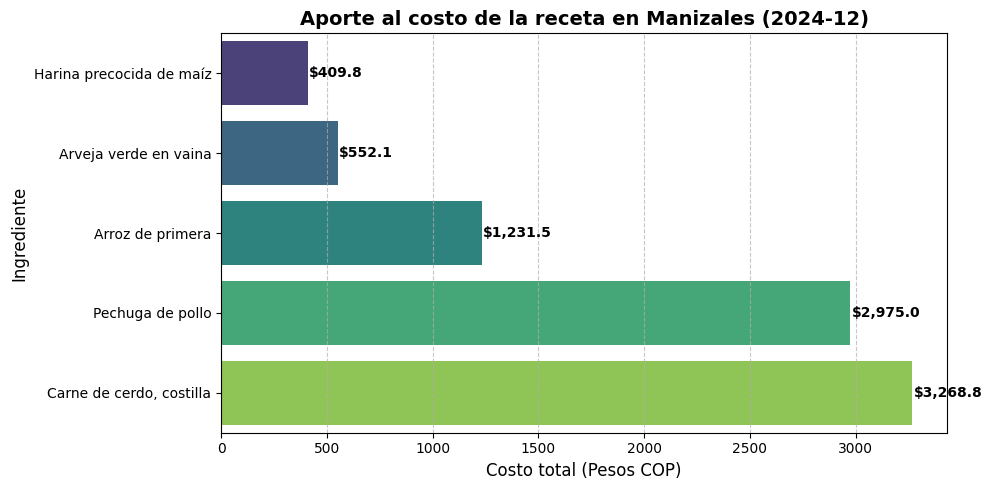

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar los datos para la ciudad y el mes indicados
df_filtrado = df[(df['ciudad'] == CIUDAD) & (df['fecha'] == MES)]

# 2. Calcular el precio promedio por kilo para cada producto en la receta
precios_promedio = df_filtrado[df_filtrado['producto'].isin(RECETA)].groupby('producto')['precio_kg'].mean()

# 3. Calcular el costo total aportado por cada ingrediente (kilos de la receta * precio promedio por kilo)
costos_ingredientes = {prod: kilos * precios_promedio[prod] for prod, kilos in RECETA.items() if prod in precios_promedio}

# Convertir a una serie de pandas para graficar fácilmente y ordenar de menor a mayor
serie_costos = pd.Series(costos_ingredientes).sort_values()

# 4. Diseñar y mostrar la gráfica
plt.figure(figsize=(10, 5))
sns.barplot(x=serie_costos.values, y=serie_costos.index, palette='viridis')

plt.title(f'Aporte al costo de la receta en {CIUDAD} ({MES})', fontsize=14, fontweight='bold')
plt.xlabel('Costo total (Pesos COP)', fontsize=12)
plt.ylabel('Ingrediente', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Mostrar etiquetas de valor al final de cada barra
for i, valor in enumerate(serie_costos.values):
    plt.text(valor + 5, i, f'${valor:,.1f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 4 · Momento 3 — Explicar

🗣️ Media página del equipo: confronten P1 y P2, expliquen cómo decidieron los nombres oficiales y completen la frase: **«Un pipeline es una composición de funciones porque…»**

---
## 🤖 Protocolo de IA

Las reglas de siempre siguen vigentes: intento propio, la IA no es autoridad final y todo uso va en la bitácora individual. Para la cacería estrella pregunten a una IA, sin contexto: *«¿cuánto cuesta hacer un sancocho para seis personas en Colombia?»*. Guarden la respuesta y la fecha. En la sesión 2 la compararán con el índice construido sobre datos oficiales.

**Próxima sesión:** el índice en el tiempo, los picos históricos, el duelo de ciudades, la conmutatividad y la unidad sancocho. Averigüen antes qué ingredientes lleva el plato de su casa.